# Principal Component Analysis in Python, Line by Line

**Unsupervised Lab · CSIT843A Lecture 4** · College of Computer Studies, University of Technology Bahrain  
Prepared by **Eng. Saeed Serwan Abdulsattar**

Interactive version with hover-to-explain code: **https://saeedserwan.github.io/unsupervised/code-pca.html**

A complete, runnable notebook that reduces 13 chemical measurements of 178 wines to a handful of principal components. You will standardise, fit PCA, read the scree plot, choose the number of components with three rules, interpret the loadings and draw a biplot. Hover over (or tap) any line of code to see what it does.

**You will learn to:**

1. See why PCA needs standardised data
2. Read explained variance and draw a scree plot
3. Choose the number of components (90% rule, Kaiser, elbow)
4. Interpret loadings and draw a biplot
5. Use PCA before clustering

> Run the cells from top to bottom (Shift + Enter). After each code cell, a **Line by line** note explains what every line does.

## 1. Import the libraries

In [1]:
%config InlineBackend.figure_format = "retina"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

plt.rcParams["figure.figsize"] = (7, 4.5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#ececec"
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]

**Line by line**

1. `%config InlineBackend.figure_format = "retina"`  
   A Jupyter setting (not Python): sharper plots on high-resolution screens.
2. `import numpy as np`  
   NumPy: arrays and maths.
3. `import pandas as pd`  
   pandas: tables.
4. `import matplotlib.pyplot as plt`  
   Matplotlib: charts.
5. `from sklearn.preprocessing import StandardScaler`  
   Rescales each column to mean 0, standard deviation 1.
6. `from sklearn.decomposition import PCA`  
   Principal component analysis.
7. `from sklearn.cluster import KMeans`  
   K-means, used at the end to cluster in PC space.
8. `from sklearn.metrics import adjusted_rand_score`  
   Compares two groupings (1 = identical).
9. `plt.rcParams["figure.figsize"] = (7, 4.5)`  
   Default figure size (width, height) in inches.
10. `plt.rcParams["axes.spines.top"] = False` …  
   A cleaner look: hide the top and right borders of every chart.
11. `plt.rcParams["axes.grid"] = True` …  
   Light grid lines make values easier to read.
12. `COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]`  
   The same six cluster colours as the website, in a fixed order.

## 2. Load the dataset

The wine dataset has **178 wines** from **three cultivars** (grape growers) and **13 chemical measurements**. The `cultivar` column is the answer key: we will **not** give it to PCA, only use it afterwards to colour the plots.

In [2]:
url = "https://raw.githubusercontent.com/SaeedSerwan/unsupervised/main/data/wine.csv"
df = pd.read_csv(url)
X = df.drop(columns="cultivar")
y = df["cultivar"]
print("X:", X.shape, "  cultivars:", sorted(y.unique().tolist()))
X.head()

X: (178, 13)   cultivars: [1, 2, 3]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280_od315,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


**Line by line**

1. `url = "https://raw.githubusercontent.com/SaeedSerwan/unsupervised/main/data/wine.csv"`  
   The file's web address.
2. `df = pd.read_csv(url)`  
   Read it into a DataFrame.
3. `X = df.drop(columns="cultivar")`  
   The 13 measurement columns: the only thing PCA will see.
4. `y = df["cultivar"]`  
   The cultivar (1, 2 or 3), kept aside for colouring plots.
5. `print("X:", X.shape, "  cultivars:", sorted(y.unique().tolist()))`  
   178 rows × 13 columns, and the three cultivar codes.
6. `X.head()`  
   The first five wines.

## 3. Why we must standardise

PCA chases variance. Look at how differently the columns are scaled.

In [3]:
X.var().sort_values(ascending=False).round(2).head(6)

proline              99166.72
magnesium              203.99
alcalinity_of_ash       11.15
color_intensity          5.37
malic_acid               1.25
flavanoids               1.00
dtype: float64

**Line by line**

1. `X.var().sort_values(ascending=False).round(2).head(6)`  
   Variance of each column, largest first. Proline's variance is in the tens of thousands; most others are below 10.

In [4]:
pca_raw = PCA().fit(X)
print("PC1 share of variance (raw):", round(pca_raw.explained_variance_ratio_[0], 4))
print("Largest PC1 loading:", X.columns[np.argmax(np.abs(pca_raw.components_[0]))])

PC1 share of variance (raw): 0.9981
Largest PC1 loading: proline


**Line by line**

1. `pca_raw = PCA().fit(X)`  
   PCA on the raw, unscaled columns (a mistake, on purpose).
2. `print("PC1 share of variance (raw):", round(pca_raw.explained_variance_ratio_[0], 4))`  
   PC1 "explains" almost everything …
3. `print("Largest PC1 loading:", X.columns[np.argmax(np.abs(pca_raw.components_[0]))])`  
   … because PC1 is basically just proline, the column with the biggest numbers.

That is not a discovery, it is an artefact of the units. So we standardise first.

In [5]:
X_scaled = StandardScaler().fit_transform(X)
pca = PCA()
scores = pca.fit_transform(X_scaled)
print("scores shape:", scores.shape)

scores shape: (178, 13)


**Line by line**

1. `X_scaled = StandardScaler().fit_transform(X)`  
   Every column now has mean 0 and standard deviation 1, so each gets an equal say.
2. `pca = PCA()`  
   Keep all 13 components for now, so we can decide how many we need.
3. `scores = pca.fit_transform(X_scaled)`  
   Fit PCA (find the directions) and return every wine's scores on all 13 components.
4. `print("scores shape:", scores.shape)`  
   178 wines × 13 component scores.

## 4. How much variance does each component explain?

`explained_variance_ratio_` is the PVE of each component. Its running total is the cumulative PVE.

In [6]:
pve = pca.explained_variance_ratio_
cum = np.cumsum(pve)
table = pd.DataFrame({"PVE": pve, "cumulative": cum, "eigenvalue": pca.explained_variance_},
                     index=[f"PC{i}" for i in range(1, 14)]).round(3)
table.head(8)

,PVE,cumulative,eigenvalue
PC1,0.362,0.362,4.732
PC2,0.192,0.554,2.511
PC3,0.111,0.665,1.454
PC4,0.071,0.736,0.924
PC5,0.066,0.802,0.858
PC6,0.049,0.851,0.645
PC7,0.042,0.893,0.554
PC8,0.027,0.920,0.350


**Line by line**

1. `pve = pca.explained_variance_ratio_`  
   Proportion of variance explained by each component (they sum to 1).
2. `cum = np.cumsum(pve)`  
   Running total: how much the first k components explain together.
3. `table = pd.DataFrame({"PVE": pve, "cumulative": cum, "eigenvalue": pca.explained_variance_},` …  
   Put the three columns in one table …
4. `table.head(8)`  
   … and show the first eight components.

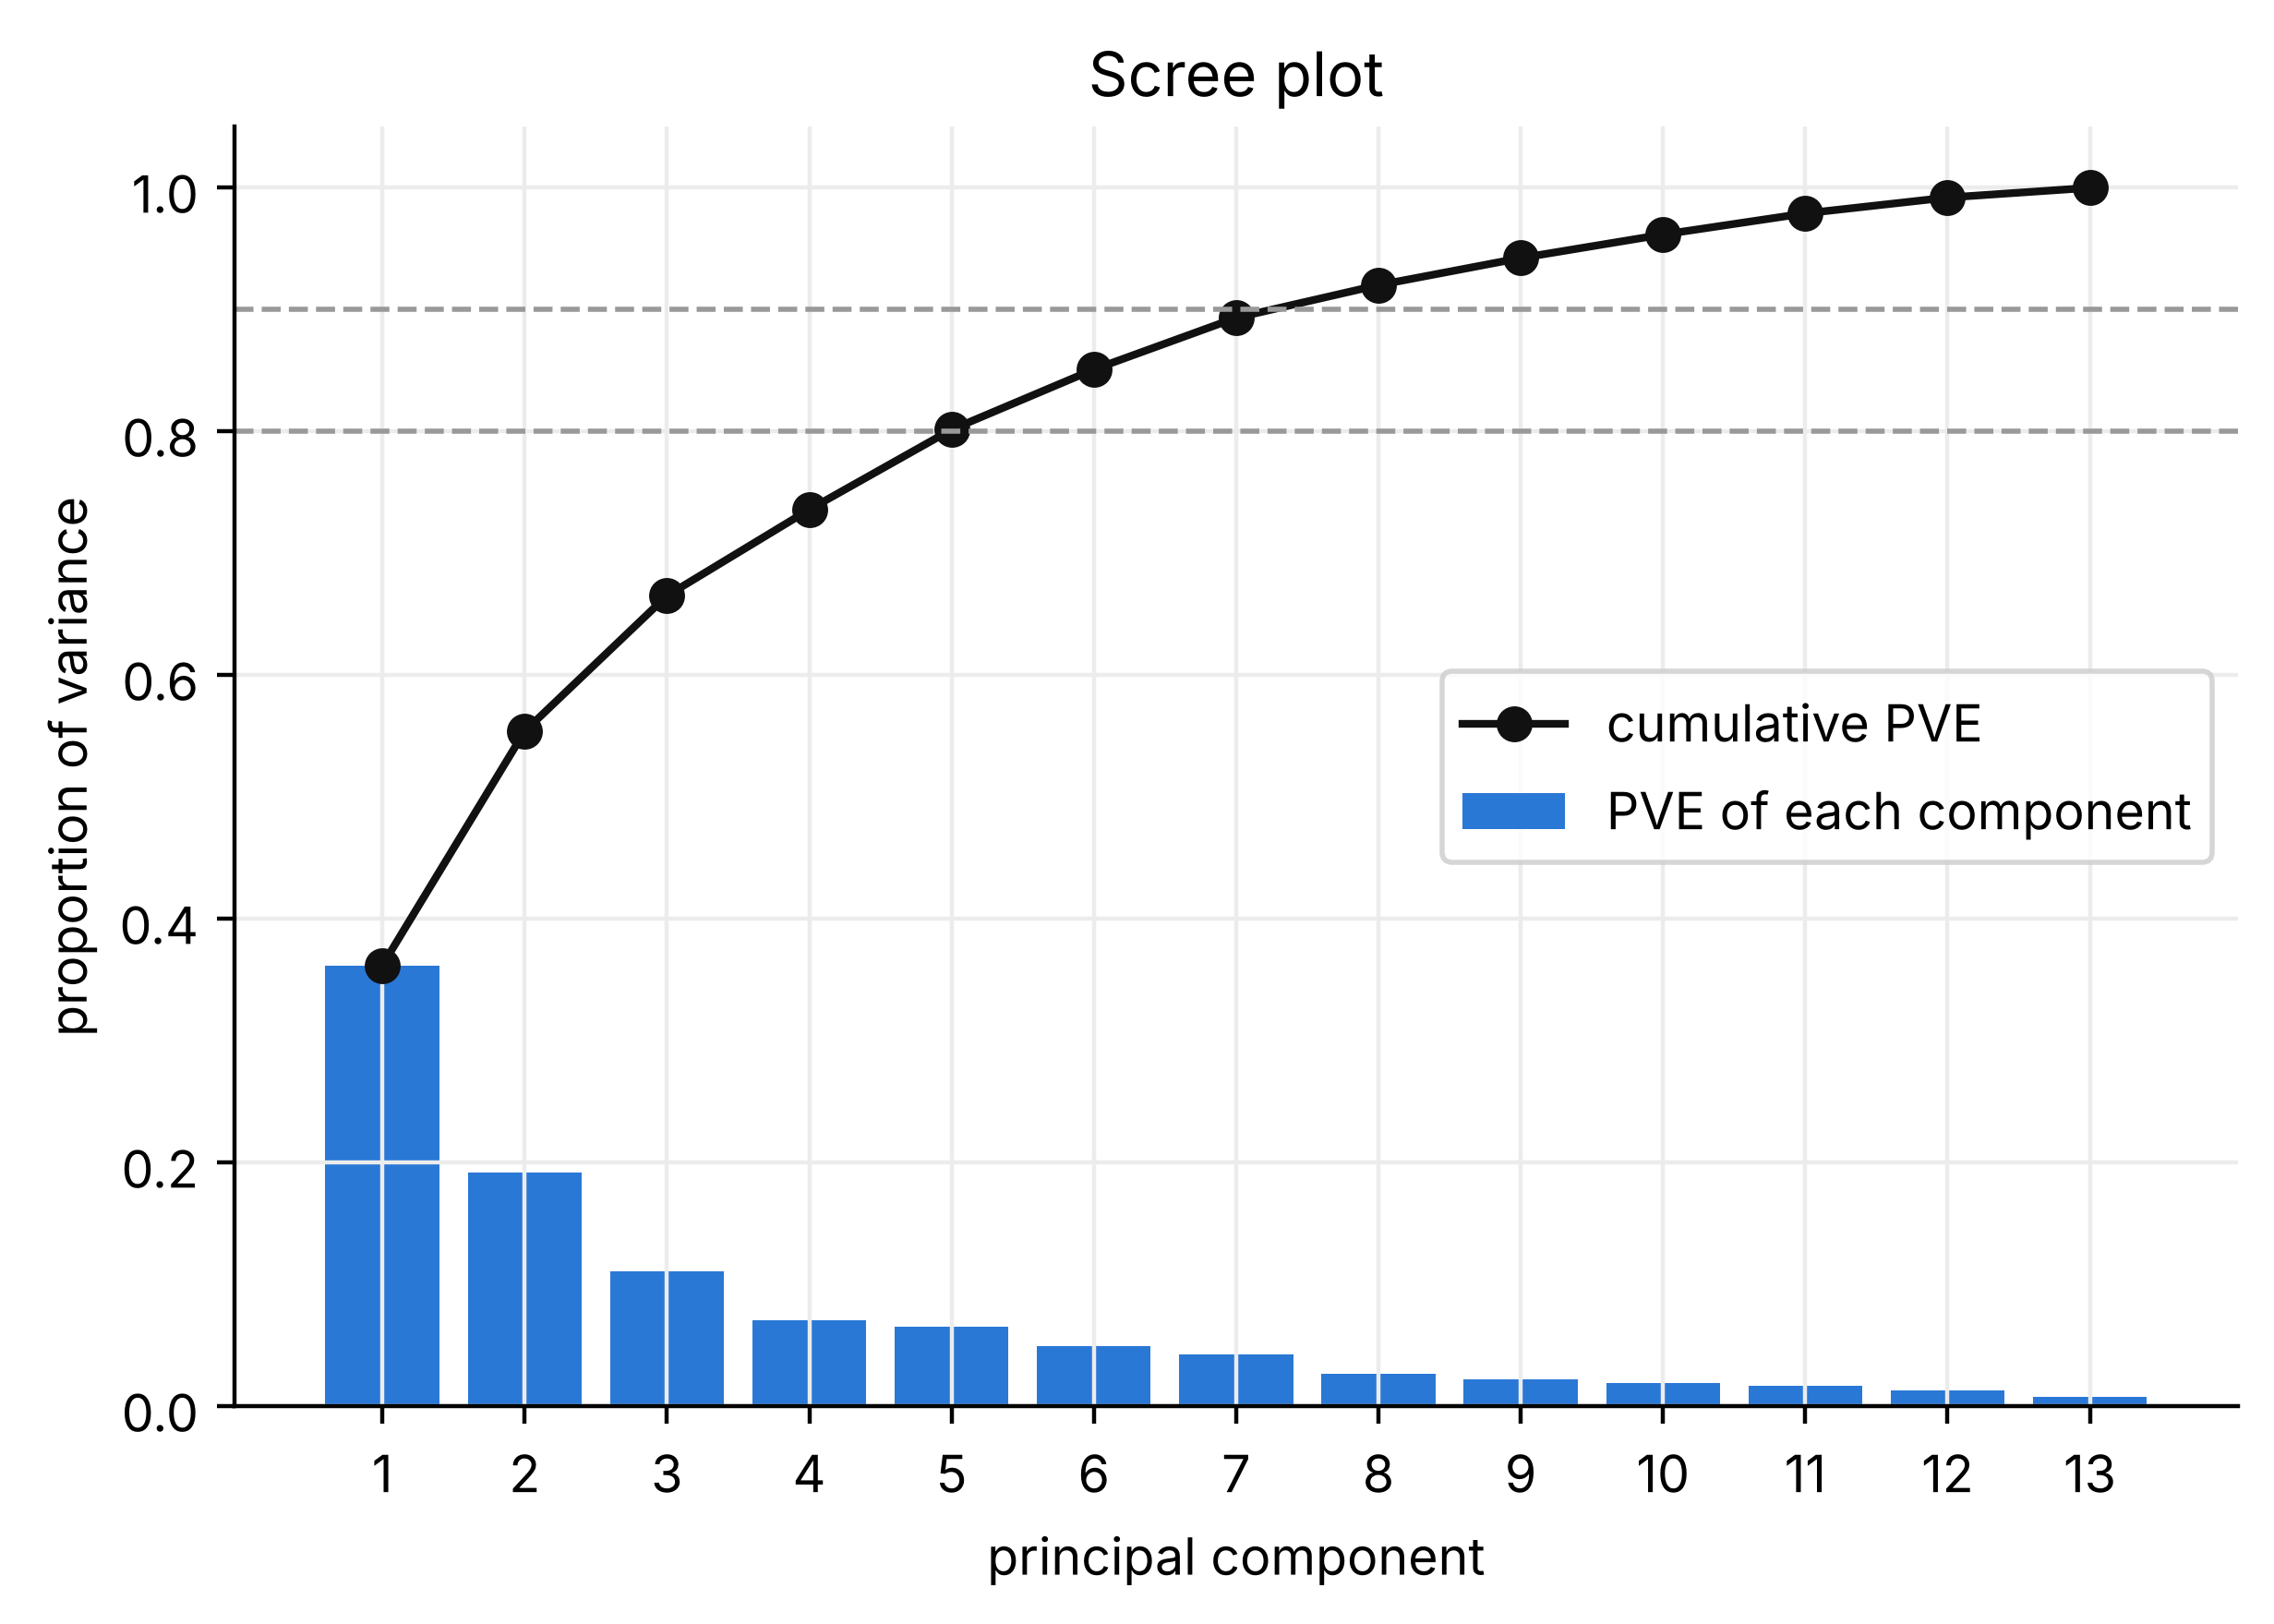

In [7]:
fig, ax = plt.subplots()
comps = np.arange(1, 14)
ax.bar(comps, pve, color="#2a78d6", label="PVE of each component")
ax.plot(comps, cum, "o-", color="#111", label="cumulative PVE")
for t in (0.8, 0.9):
    ax.axhline(t, color="#999", linestyle="--", linewidth=1)
ax.set(xlabel="principal component", ylabel="proportion of variance", xticks=comps, title="Scree plot")
ax.legend()
plt.show()

**Line by line**

1. `fig, ax = plt.subplots()`  
   A new chart.
2. `comps = np.arange(1, 14)`  
   Component numbers 1-13 for the x-axis.
3. `ax.bar(comps, pve, color="#2a78d6", label="PVE of each component")`  
   Bars: how much each component adds.
4. `ax.plot(comps, cum, "o-", color="#111", label="cumulative PVE")`  
   Line: the running total.
5. `for t in (0.8, 0.9):`  
   Draw the common thresholds …
6. `ax.axhline(t, color="#999", linestyle="--", linewidth=1)`  
   … as dashed horizontal lines at 80% and 90%.
7. `ax.set(xlabel="principal component", ylabel="proportion of variance", xticks=comps, title="Scree plot")`  
   Labels, one tick per component, title.
8. `ax.legend()`  
   Show which mark is which.
9. `plt.show()`  
   Display.

## 5. Choose the number of components

Three common rules. When they disagree, your **purpose** decides: 2 for a plot, more for feeding a model.

In [8]:
k_90 = int(np.argmax(cum >= 0.90)) + 1
k_80 = int(np.argmax(cum >= 0.80)) + 1
k_kaiser = int(np.sum(pca.explained_variance_ > 1))
print(f"80% rule: k = {k_80}")
print(f"90% rule: k = {k_90}")
print(f"Kaiser:   k = {k_kaiser}")
print(f"First 2 components keep {cum[1]:.1%} of the variance")

80% rule: k = 5
90% rule: k = 8
Kaiser:   k = 3
First 2 components keep 55.4% of the variance


**Line by line**

1. `k_90 = int(np.argmax(cum >= 0.90)) + 1`  
   90% rule: the first position where the cumulative PVE reaches 0.90 (+1 because positions start at 0).
2. `k_80 = int(np.argmax(cum >= 0.80)) + 1`  
   The same with an 80% threshold.
3. `k_kaiser = int(np.sum(pca.explained_variance_ > 1))`  
   Kaiser rule: keep components whose eigenvalue (variance) is above 1, i.e. worth more than one standardised column.
4. `print(f"80% rule: k = {k_80}")` …  
   Print each rule's answer.
5. `print(f"First 2 components keep {cum[1]:.1%} of the variance")`  
   And what we keep if we only want a 2D picture.

In [9]:
pca90 = PCA(n_components=0.90).fit(X_scaled)
print("components kept:", pca90.n_components_)

components kept: 8


**Line by line**

1. `pca90 = PCA(n_components=0.90).fit(X_scaled)`  
   A shortcut: a number between 0 and 1 asks scikit-learn to keep just enough components for that share of variance.
2. `print("components kept:", pca90.n_components_)`  
   Same answer as the 90% rule above.

## 6. 3D → 2D → 1D on simple data

Before interpreting the wine components, see how the PVE reveals a dataset's true dimension. We make three 3D datasets with NumPy: a flat sheet, a cigar and a round ball.

In [10]:
rng = np.random.default_rng(0)
n = 300
a, b, c = rng.normal(size=(3, n))
shapes = {
    "flat sheet": np.c_[a + b, a - b, 0.05 * c],
    "cigar": np.c_[a, a + 0.1 * b, a + 0.1 * c],
    "round ball": np.c_[a, b, c],
}
for name, data in shapes.items():
    p = PCA().fit(data).explained_variance_ratio_
    print(f"{name:11s} PVE = {np.round(p, 3)}  cumulative = {np.round(np.cumsum(p), 3)}")

flat sheet  PVE = [0.53  0.47  0.001]  cumulative = [0.53  0.999 1.   ]
cigar       PVE = [0.996 0.003 0.001]  cumulative = [0.996 0.999 1.   ]
round ball  PVE = [0.377 0.331 0.292]  cumulative = [0.377 0.708 1.   ]


**Line by line**

1. `rng = np.random.default_rng(0)`  
   A random number generator with a fixed seed, so the results repeat.
2. `n = 300`  
   300 points per dataset.
3. `a, b, c = rng.normal(size=(3, n))`  
   Three columns of standard normal noise.
4. `shapes = {`  
   Each dataset is an n × 3 array:
5. `"flat sheet": np.c_[a + b, a - b, 0.05 * c],`  
   spread in two directions, almost none in the third
6. `"cigar": np.c_[a, a + 0.1 * b, a + 0.1 * c],`  
   all three columns nearly the same: one direction
7. `"round ball": np.c_[a, b, c],` …  
   independent columns: no special direction
8. `for name, data in shapes.items():`  
   For each dataset …
9. `p = PCA().fit(data).explained_variance_ratio_`  
   … fit PCA and get the PVE of the three components …
10. `print(f"{name:11s} PVE = {np.round(p, 3)}  cumulative = {np.round(np.cumsum(p), 3)}")`  
   … and print them with the running total.

- **Flat sheet**: two components keep ~100% → it is really **2D**: keep 2.
- **Cigar**: one component keeps ~99% → it is really **1D**: keep 1.
- **Round ball**: about a third each → nothing to drop: PCA cannot reduce it.

The interactive version, with seven datasets, is on the [PCA page](https://saeedserwan.github.io/unsupervised/pca.html#how-many).

## 7. Plot the wines in 2D

The first two score columns are each wine's position on PC1 and PC2. We colour by cultivar only to *check* the result; PCA never saw it.

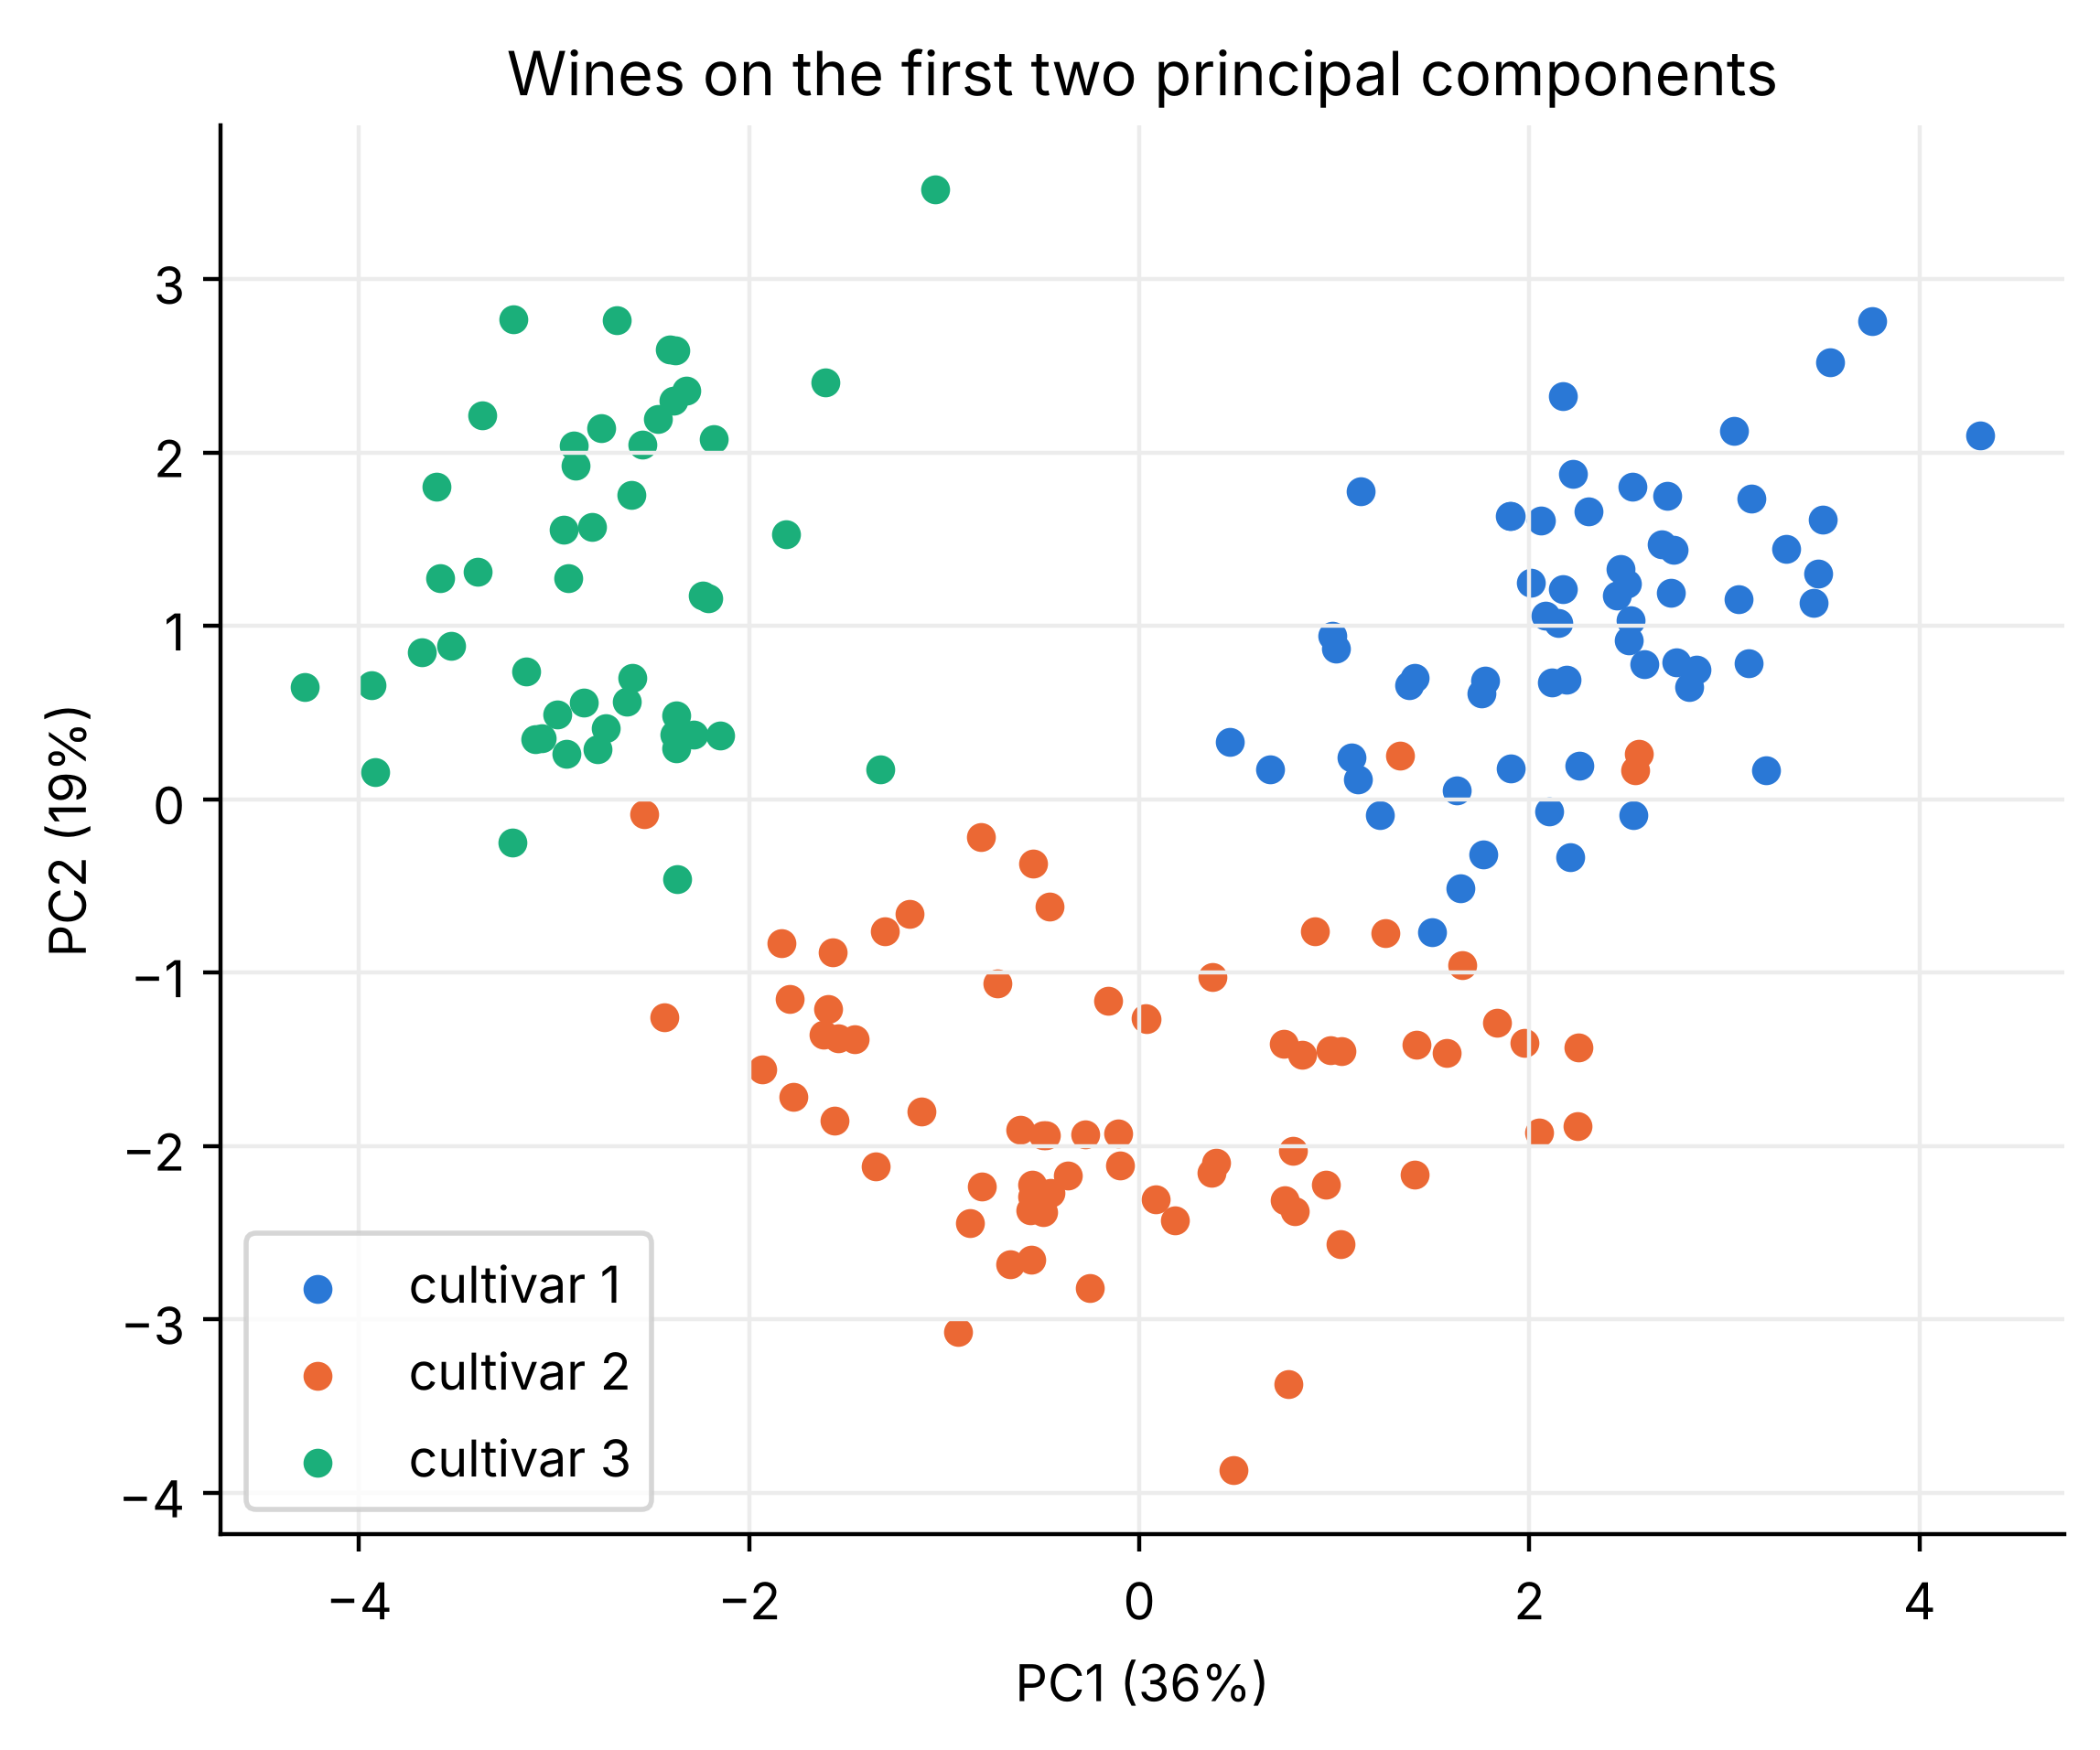

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for i, cult in enumerate([1, 2, 3]):
    m = (y == cult).to_numpy()
    ax.scatter(scores[m, 0], scores[m, 1], s=22, color=COLORS[i], label=f"cultivar {cult}")
ax.set(xlabel=f"PC1 ({pve[0]:.0%})", ylabel=f"PC2 ({pve[1]:.0%})", title="Wines on the first two principal components")
ax.legend()
plt.show()

**Line by line**

1. `fig, ax = plt.subplots(figsize=(6.5, 5))`  
   A slightly squarer figure.
2. `for i, cult in enumerate([1, 2, 3]):`  
   One cultivar at a time, so each gets its own colour and legend entry.
3. `m = (y == cult).to_numpy()`  
   True for the wines of this cultivar.
4. `ax.scatter(scores[m, 0], scores[m, 1], s=22, color=COLORS[i], label=f"cultivar {cult}")`  
   Their PC1 and PC2 scores.
5. `ax.set(xlabel=f"PC1 ({pve[0]:.0%})", ylabel=f"PC2 ({pve[1]:.0%})", title="Wines on the first two principal components")`  
   Axis labels show how much variance each PC holds.
6. `ax.legend()`  
   Legend.
7. `plt.show()`  
   Display.

Thirteen columns squeezed into two, and the three cultivars still separate almost perfectly.

## 8. What are the components made of? Loadings

`components_` holds the loadings: one row per component, one column per original feature. Each row has length 1.

In [12]:
loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])
loadings.sort_values("PC1").round(2)

,PC1,PC2
nonflavanoid_phenols,-0.30,0.03
malic_acid,-0.25,0.22
alcalinity_of_ash,-0.24,-0.01
color_intensity,-0.09,0.53
ash,-0.00,0.32
magnesium,0.14,0.30
alcohol,0.14,0.48
proline,0.29,0.36
hue,0.30,-0.28
proanthocyanins,0.31,0.04


**Line by line**

1. `loadings = pd.DataFrame(pca.components_[:2].T, index=X.columns, columns=["PC1", "PC2"])`  
   The first two rows, transposed so features are rows.
2. `loadings.sort_values("PC1").round(2)`  
   Sorted by their PC1 loading, from most negative to most positive.

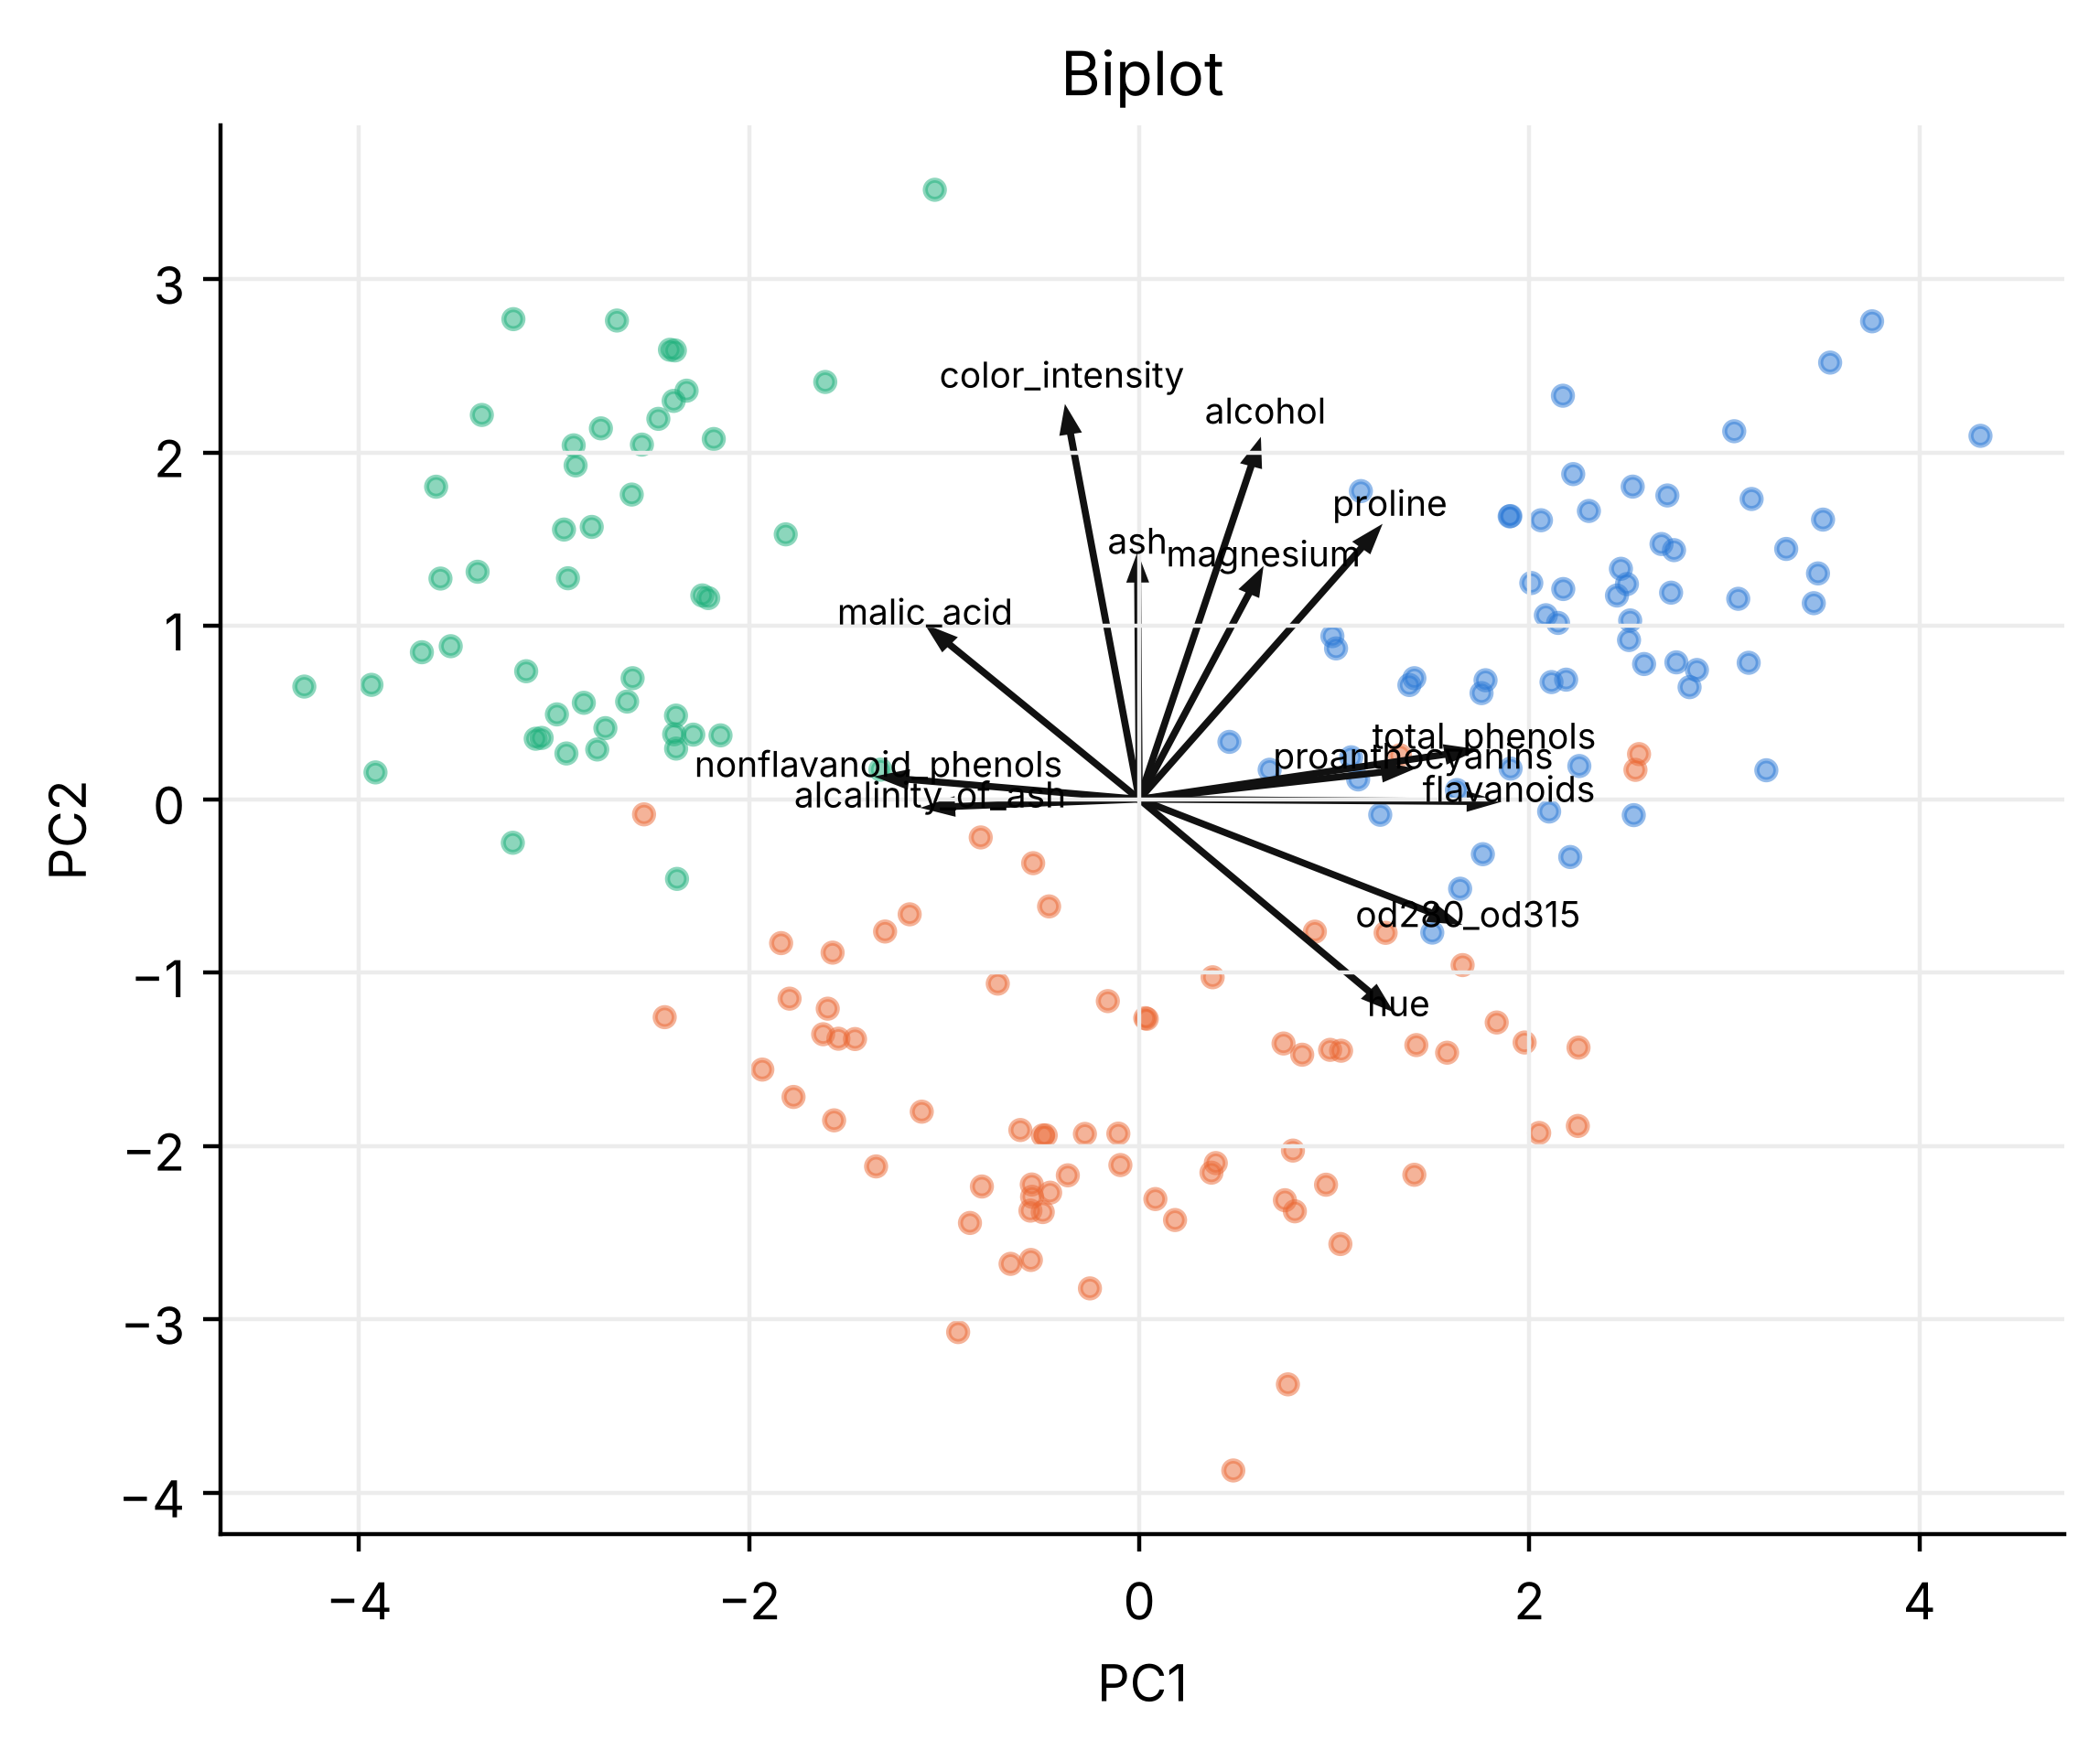

In [13]:
fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(scores[:, 0], scores[:, 1], s=14, c=[COLORS[c - 1] for c in y], alpha=0.5)
scale = 4
for name, (l1, l2) in loadings.iterrows():
    ax.arrow(0, 0, l1 * scale, l2 * scale, color="#111", width=0.01, head_width=0.08)
    ax.text(l1 * scale * 1.12, l2 * scale * 1.12, name, fontsize=7, ha="center")
ax.set(xlabel="PC1", ylabel="PC2", title="Biplot")
plt.show()

**Line by line**

1. `fig, ax = plt.subplots(figsize=(6.5, 5))`  
   A biplot: scores and loadings on one chart.
2. `ax.scatter(scores[:, 0], scores[:, 1], s=14, c=[COLORS[c - 1] for c in y], alpha=0.5)`  
   The wines, faded.
3. `scale = 4`  
   Loadings are at most 1 long; stretch the arrows so they are visible next to the scores.
4. `for name, (l1, l2) in loadings.iterrows():`  
   For each feature …
5. `ax.arrow(0, 0, l1 * scale, l2 * scale, color="#111", width=0.01, head_width=0.08)`  
   … draw an arrow from the origin in its loading direction …
6. `ax.text(l1 * scale * 1.12, l2 * scale * 1.12, name, fontsize=7, ha="center")`  
   … and label it near the tip.
7. `ax.set(xlabel="PC1", ylabel="PC2", title="Biplot")`  
   Labels.
8. `plt.show()`  
   Display.

Features pointing the same way are positively correlated; arrows pointing towards a group of wines show what is high for those wines. Flavanoids and total phenols pull towards cultivar 1, colour intensity and malic acid towards cultivar 3.

## 9. What do we lose? Reconstruction error

Keep k components, map back to the original space with `inverse_transform`, and measure the error.

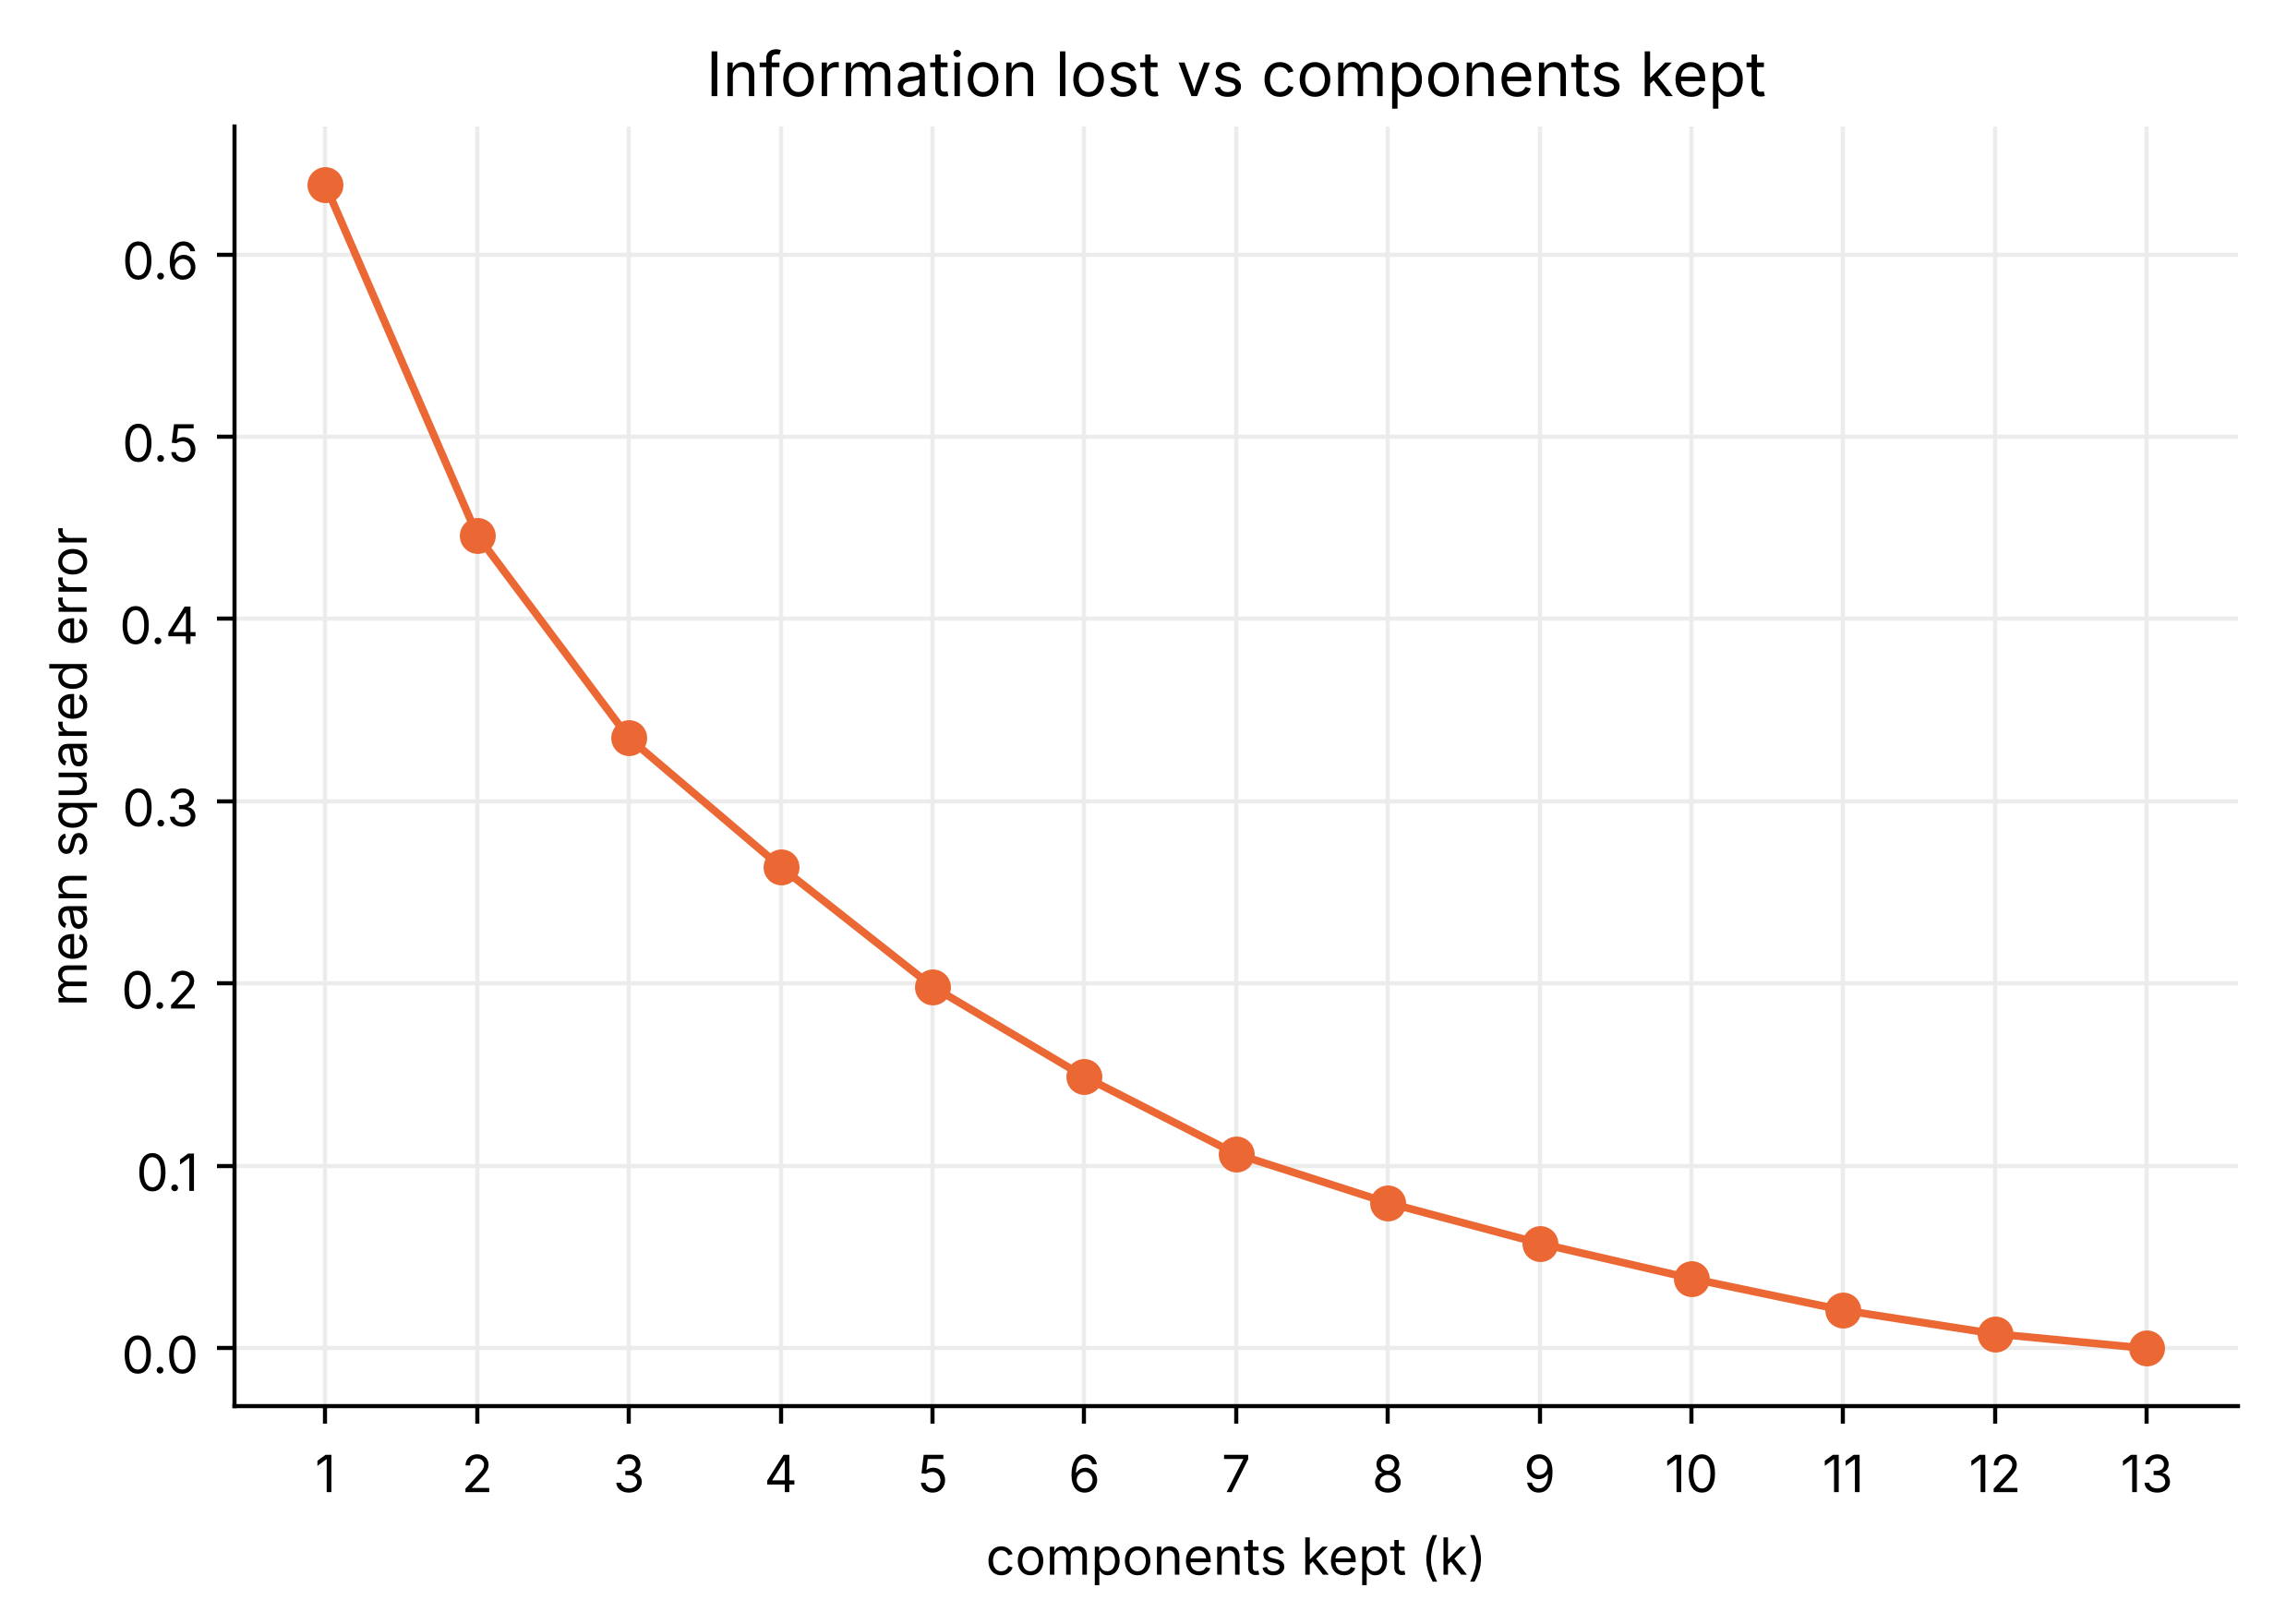

In [14]:
errors = []
for k in range(1, 14):
    p = PCA(n_components=k).fit(X_scaled)
    X_back = p.inverse_transform(p.transform(X_scaled))
    errors.append(np.mean((X_scaled - X_back) ** 2))

fig, ax = plt.subplots()
ax.plot(range(1, 14), errors, "o-", color="#eb6834")
ax.set(xlabel="components kept (k)", ylabel="mean squared error", xticks=range(1, 14), title="Information lost vs components kept")
plt.show()

**Line by line**

1. `errors = []`  
   One error per k.
2. `for k in range(1, 14):`  
   k = 1 … 13 components.
3. `p = PCA(n_components=k).fit(X_scaled)`  
   Keep only k components.
4. `X_back = p.inverse_transform(p.transform(X_scaled))`  
   Compress to k numbers per wine, then rebuild all 13 columns from them.
5. `errors.append(np.mean((X_scaled - X_back) ** 2))`  
   Mean squared reconstruction error.
6. `fig, ax = plt.subplots()`  
   A new chart.
7. `ax.plot(range(1, 14), errors, "o-", color="#eb6834")`  
   Error against k.
8. `ax.set(xlabel="components kept (k)", ylabel="mean squared error", xticks=range(1, 14), title="Information lost vs components kept")`  
   Labels.
9. `plt.show()`  
   Display.

The error equals the share of variance we dropped: it is $1 - $ cumulative PVE. Keeping all 13 components rebuilds the data perfectly (error 0).

## 10. PCA before clustering

A common pipeline: standardise → PCA → K-means. Clustering on a few component scores removes noise and makes results easy to plot.

In [15]:
Z2 = scores[:, :2]
labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z2)
print(pd.crosstab(y, labels, rownames=["cultivar"], colnames=["cluster"]))
print("Adjusted Rand index:", round(adjusted_rand_score(y, labels), 3))

cluster    0   1   2
cultivar            
1          0  59   0
2         65   5   1
3          0   0  48
Adjusted Rand index: 0.895


**Line by line**

1. `Z2 = scores[:, :2]`  
   Each wine's first two component scores.
2. `labels = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z2)`  
   Three clusters in the 2D PC space.
3. `print(pd.crosstab(y, labels, rownames=["cultivar"], colnames=["cluster"]))`  
   Compare clusters with the true cultivars (which K-means never saw).
4. `print("Adjusted Rand index:", round(adjusted_rand_score(y, labels), 3))`  
   Close to 1 means the clusters match the cultivars well.

## 11. Summary

| Step | Code |
|---|---|
| Standardise | `X_scaled = StandardScaler().fit_transform(X)` |
| Fit all components | `pca = PCA().fit(X_scaled)` |
| Variance explained | `pca.explained_variance_ratio_`, `np.cumsum(...)` |
| Choose k | 90% rule, Kaiser (`explained_variance_ > 1`), elbow, or `PCA(n_components=0.90)` |
| Scores | `pca.transform(X_scaled)` |
| Loadings | `pca.components_` |
| Rebuild | `pca.inverse_transform(scores)` |

## 12. Exercises

1. Repeat section 7 **without** standardising. What happens to the picture, and why?
2. How many components does an 80% threshold keep? A 95% threshold?
3. Which three features have the largest absolute loadings on PC2? Give PC2 a name.
4. Cluster on 5 components instead of 2. Does the adjusted Rand index improve?